In [3]:
from random import random, choice
from time import time
import matplotlib.pyplot as plt
from tqdm import tqdm
import math

In [4]:
def recherche_dichotomique(T, x):
    if len(T) == 0:
        return
        
    deb = 0
    fin = len(T)

    while deb <= fin:
        mid = int((deb + fin) / 2)
        if x < T[mid]:
            fin = mid
        elif T[mid] < x:
            deb = mid + 1
        else:
            return mid

In [5]:
def generer_tableau_trie(n):
    return [i for i in range(1, n + 1)]

In [6]:
def generer_valeur_a_chercher(T):
    return T[0]

In [7]:
def mesurer_temps_execution(n, nb_repetitions):
    tailles = [i for i in range(1, n + 1, 100)] # On ne teste pas systématiquement toutes les tailles de tableau entre 1 et n, mais on utilise un pas de 100: cela ne modifie pas la représentation graphique, mais ça réduit par 100 le nombre de tableaux à traiter
    temps = []

    for taille in tqdm(tailles):
        T = generer_tableau_trie(taille)
        x = generer_valeur_a_chercher(T)

        mean_time = 0
        for i in range(nb_repetitions):
            temps_depart = time()
            recherche_dichotomique(T, x)
            temps_recherche = time() - temps_depart
            mean_time += temps_recherche/nb_repetitions
        
        temps.append(mean_time)

    return tailles, temps

In [8]:
tailles, temps = mesurer_temps_execution(1000000, 10000)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [03:17<00:00, 50.66it/s]


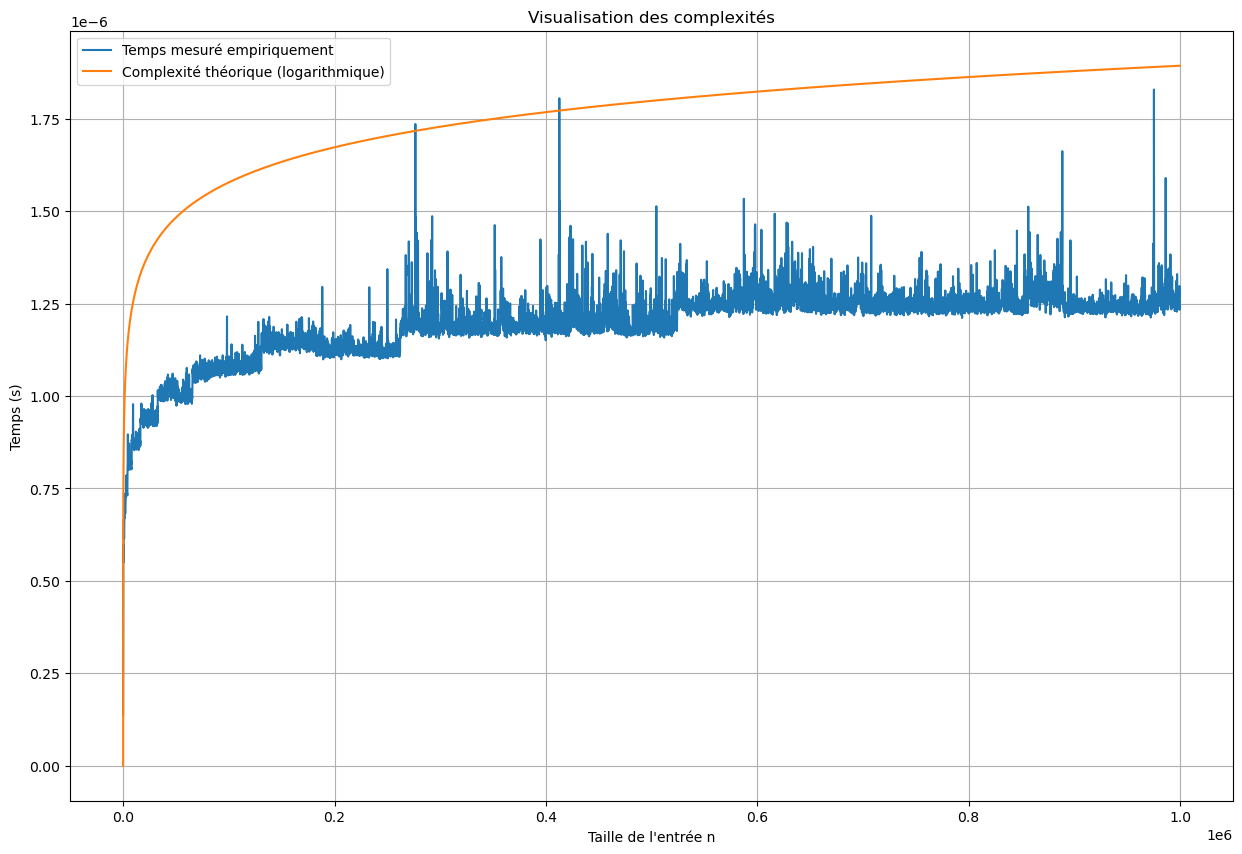

In [9]:
complexite_asymptotique_theorique_log = [(0.95 * 10 ** (-7)) * math.log2(valeur) for valeur in tailles]

fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(tailles, temps, label="Temps mesuré empiriquement")
ax.plot(tailles, complexite_asymptotique_theorique_log, label="Complexité théorique (logarithmique)")
ax.set(xlabel='Taille de l\'entrée n', ylabel='Temps (s)', title="Visualisation des complexités")
#ax.set_yscale('log')
ax.grid()
plt.legend()

plt.show()